In [1]:
# from CITNP.datasets.dataset_generator import QueuedInterventionDatasetGenerator
from CITNP.datasets.dataset_generator import InterventionDatasetGenerator

In [2]:
import numpy as np


few_nodes_graph_degrees = {
    5: np.arange(5, 10, dtype=int).tolist(),
    6: np.arange(3, 15, dtype=int).tolist(),
    7: np.arange(4, 21, dtype=int).tolist(),
    8: np.arange(4, 28, dtype=int).tolist(),
    9: np.arange(5, 36, dtype=int).tolist(),
    10: np.arange(5, 45, dtype=int).tolist(),
    11: np.arange(6, 55, dtype=int).tolist(),
    12: np.arange(6, 66, dtype=int).tolist(),
}
large_graph_degrees = {
    k: np.arange(k // 2, 6 * k, dtype=int).tolist() for k in range(13, 51)
}
graph_degrees = {**few_nodes_graph_degrees, **large_graph_degrees}


generator = InterventionDatasetGenerator(
    function_generator="simplegp",
    num_variables=[2],
    sample_size=1000,
    batch_size=1,
    graph_type=["ER"],
    graph_degrees=[1],
    iterations_per_epoch=20,
    intervention_range_multiplier=1,
)

Intervention: tensor(0)
Outcome: 1


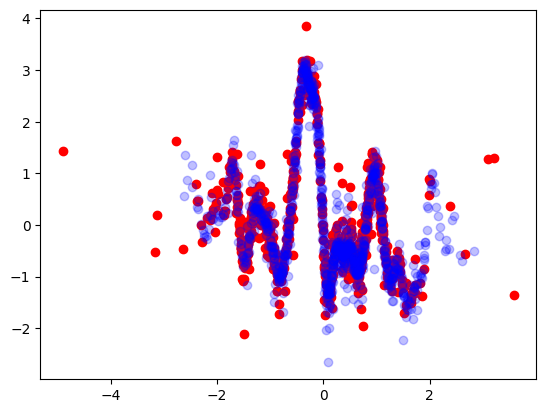

Intervention: tensor(0)
Outcome: 1


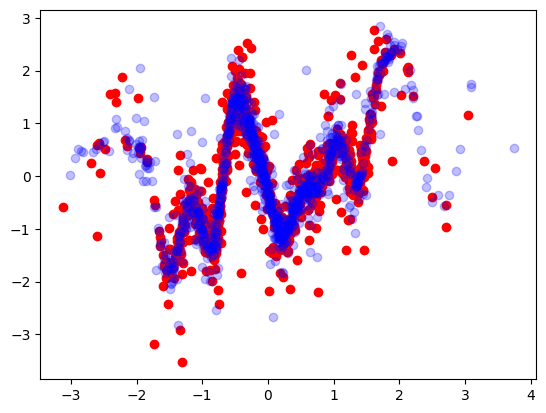

Intervention: tensor(1)
Outcome: 0


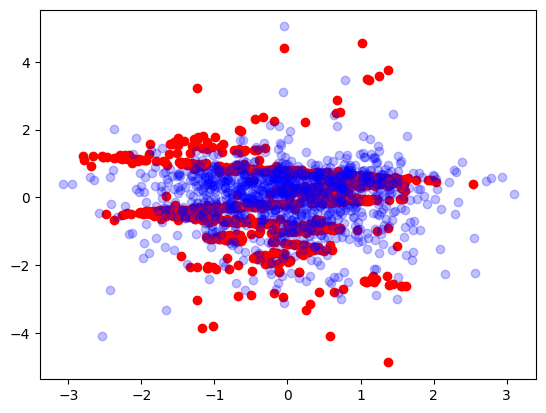

Intervention: tensor(1)
Outcome: 0


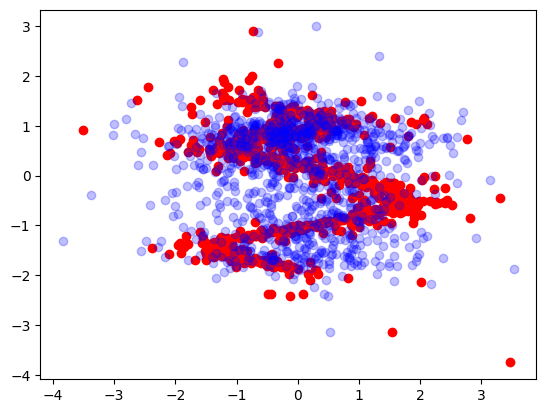

Intervention: tensor(1)
Outcome: 0


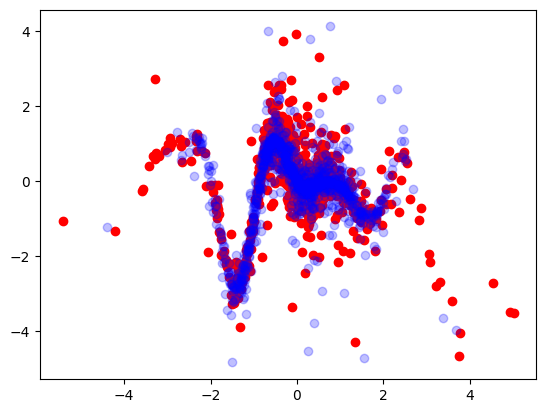

Intervention: tensor(1)
Outcome: 0


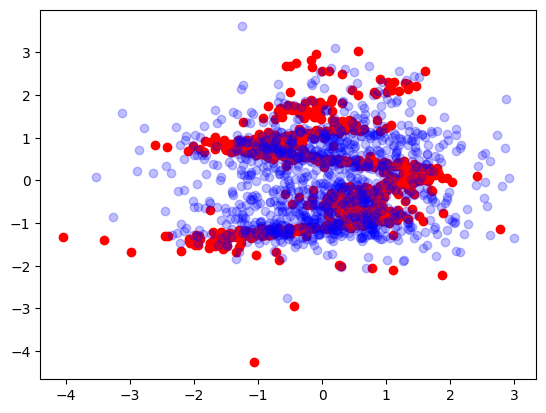

Intervention: tensor(1)
Outcome: 0


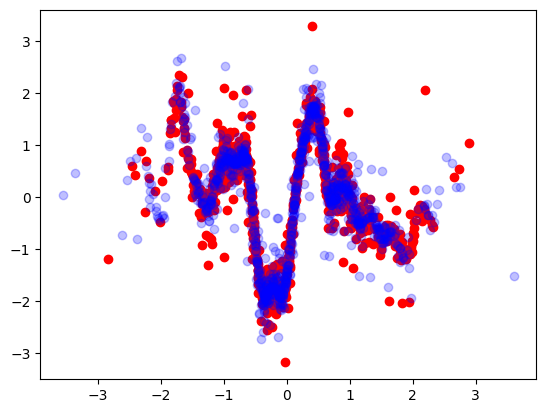

Intervention: tensor(1)
Outcome: 0


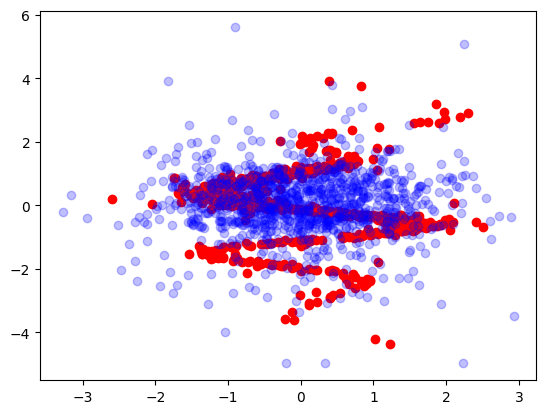

Intervention: tensor(1)
Outcome: 0


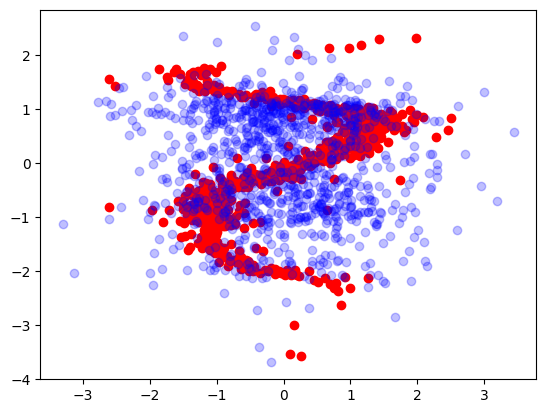

Intervention: tensor(1)
Outcome: 0


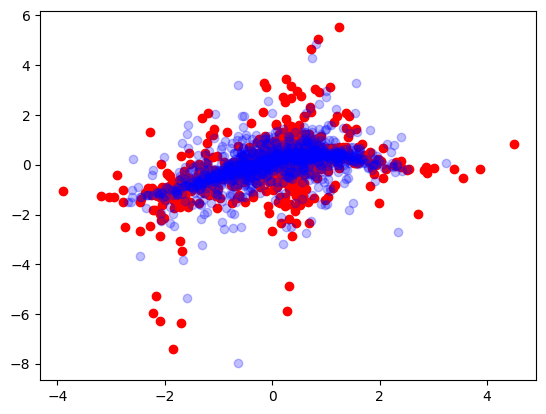

Intervention: tensor(1)
Outcome: 0


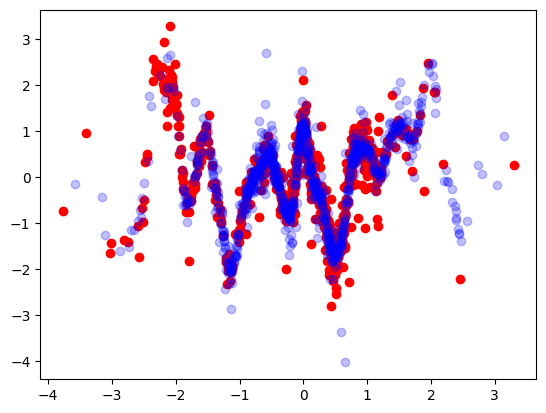

Intervention: tensor(1)
Outcome: 0


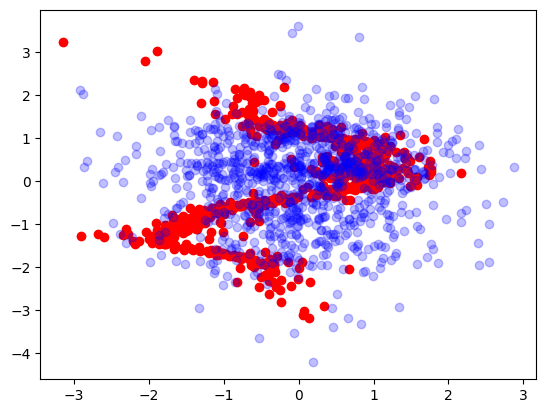

Intervention: tensor(0)
Outcome: 1


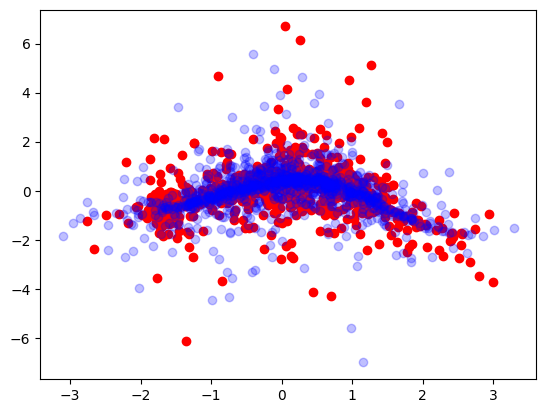

Intervention: tensor(1)
Outcome: 0


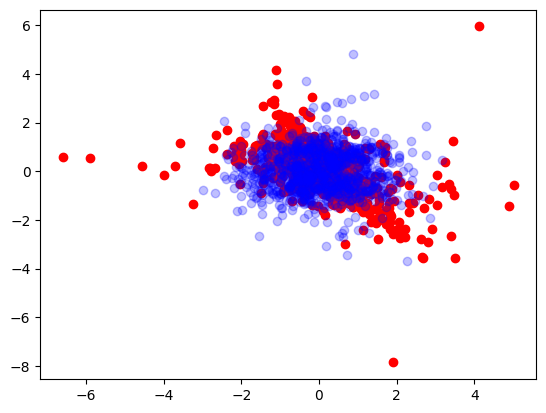

Intervention: tensor(0)
Outcome: 1


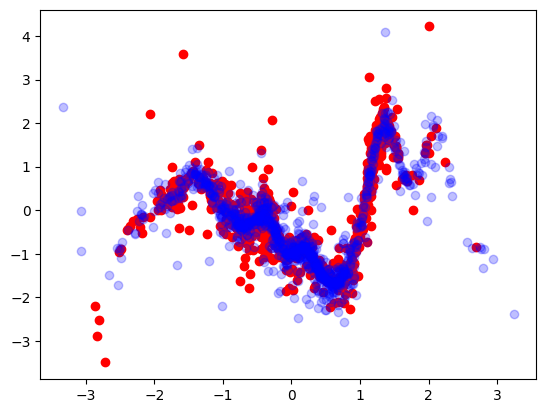

Intervention: tensor(0)
Outcome: 1


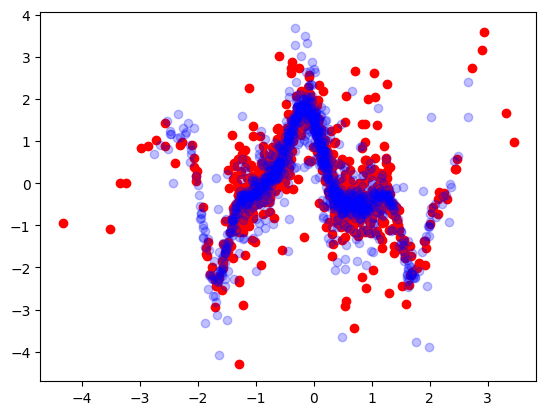

Intervention: tensor(0)
Outcome: 1


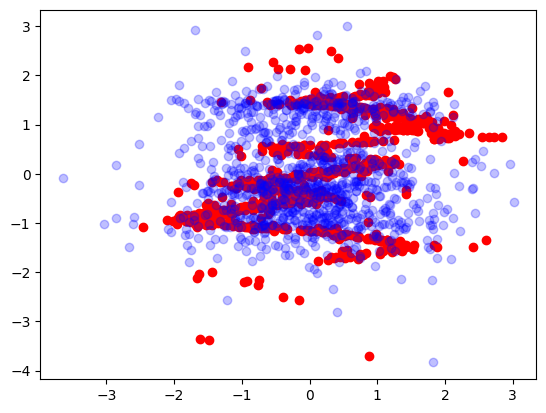

Intervention: tensor(0)
Outcome: 1


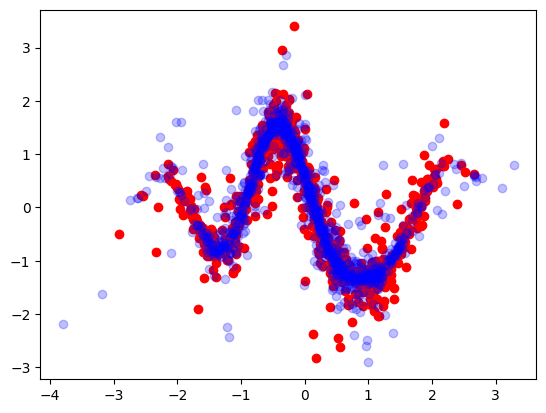

Intervention: tensor(1)
Outcome: 0


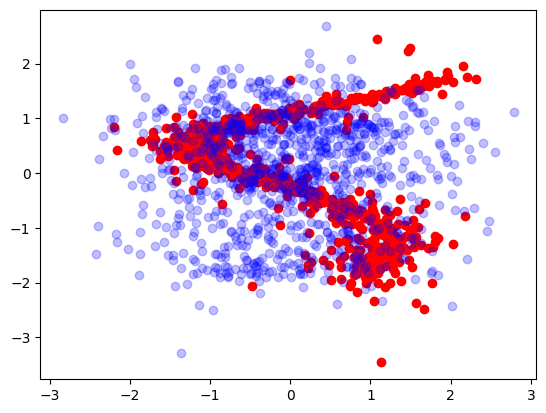

Intervention: tensor(0)
Outcome: 1


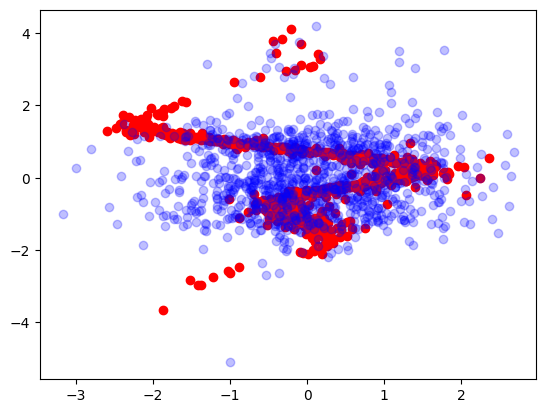

<Figure size 640x480 with 0 Axes>

In [3]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from CITNP.utils.datautils import sample_outcome_index


data_loader = DataLoader(generator, batch_size=None)


for idx, batch in enumerate(data_loader):
    (
        obs_data_array,
        int_data_array,
        causal_graphs_array,
        intvn_indices,
        variable_counts,
        masks,
    ) = batch

    # Sample outcome index that is not the same as the intervention index
    outcome_index = sample_outcome_index(variable_counts, intvn_indices)

    plt.scatter(
        obs_data_array[0][:, intvn_indices[0]],
        obs_data_array[0][:, outcome_index[0]],
        c="r",
    )

    plt.scatter(
        int_data_array[0][:, intvn_indices[0]],
        int_data_array[0][:, outcome_index[0]],
        c="b",
        alpha=0.25,
    )
    # print("Causal graph:", causal_graphs_array[0])
    print("Intervention:", intvn_indices[0])
    print("Outcome:", outcome_index[0])
    plt.show()
    plt.clf()


In [12]:
int_data_array[0, :, outcome_index].std()

tensor(1.2205, dtype=torch.float64)

In [4]:
import h5py
from pathlib import Path

path = Path(
    "/vol/bitbucket/ad6013/Research/CausalInferenceNeuralProcess/CITNP/datasets/synth_training_data/20var_ER4_neuralgplvm_1000/test/data_idx20_0.hdf5"
)

with h5py.File(path, "r") as f:
    obs_data = f["obs_data"][:]
    int_data = f["int_data"][:]
    causal_graphs = f["causal_graphs"][:]
    intvn_indices = f["intvn_indices"][:]
    variable_counts = f["variable_counts"][:]


In [ ]:
obs_data.mean(1)

np.float64(7.544920976272351e-07)

In [10]:
int_data.std(1)

array([[1.11750991, 1.00570957, 0.96936429, ..., 1.02158475, 1.01882639,
        1.01522954],
       [1.03955604, 1.05762343, 1.06773484, ..., 0.91925716, 1.01493513,
        0.88619041],
       [0.89890587, 1.02112923, 0.9340508 , ..., 0.99845383, 0.99779631,
        1.04715687],
       ...,
       [1.00668724, 0.91080077, 0.95264477, ..., 1.02456002, 1.0013901 ,
        1.02908028],
       [1.08911719, 1.07746291, 1.00931367, ..., 1.00975187, 1.03185951,
        0.97223978],
       [1.15534716, 0.99101762, 0.97448716, ..., 0.95588582, 1.03052231,
        1.0969362 ]], shape=(100, 20))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


for i in range(10):
    x = np.random.randn(1000)

    scale = np.random.gamma(1, 1, 1000)
    y = np.random.randn(1) * x + np.random.normal(loc=np.zeros_like(scale), scale=scale)
    plt.scatter(x, y)

    plt.scatter(y, x, c="r")
    plt.show()

In [ ]:
import h5py


with

In [ ]:
( np.random.randn(1) * x + np.random.normal(loc=np.zeros_like(scale), scale=scale, size=(1,))).shape

In [ ]:
(np.random.randn(1) * x).shape

In [ ]:
np.random.normal(loc=np.zeros_like(scale), scale=scale).shape